# Лабораторная работа №3 — CNN на EuroSAT: классификация спутниковых снимков

**Датасет:** EuroSAT RGB, 27 000 снимков Sentinel-2, 64×64×3, 10 классов.
**Задача:** многоклассовая классификация изображений.
**Основная метрика:** macro-F1; дополнительно accuracy.
**Режим:** ноутбук загружает готовые `*.json`, `*.keras` и PNG; обучение не выполняется.

## 1. Заголовок и задача

**Предметная область.** Спутниковые снимки Sentinel-2 показывают, как используется земля: лес, пашня, пастбище, город, вода, дорога и т.д. Автоматическая классификация нужна для карт землепользования, мониторинга и анализа изменений.

**Формальная постановка.** Дано изображение `X ∈ R^(64×64×3)` и 10 классов `y ∈ {0,...,9}`. Требуется построить `p(y | X)`, которая по пикселям выдаёт распределение вероятностей классов. Классы: `AnnualCrop`, `Forest`, `HerbaceousVegetation`, `Highway`, `Industrial`, `Pasture`, `PermanentCrop`, `Residential`, `River`, `SeaLake`.

**Тип задачи.** Многоклассовая классификация изображений. Признаки не задаются вручную: CNN учит их из пикселей. Это не детекция объектов и не сегментация: на выходе один класс на весь снимок.

**Цель.** Обучить CNN с нуля на EuroSAT RGB, сравнить с простыми baseline и проверить, насколько результат зависит от протокола обучения, а не только от архитектуры.

**Критерий успеха.** macro-F1 заметно выше majority, random и HOG + logreg; split без пересечений; нормализация и аугментация не используют test; результат сопровождается честным обсуждением протокола и ограничений.

**Что не входит.** Сравнение архитектур по глубине и ширине, предобученные сети, learning rate schedule, разрешение 128×128, доверительный интервал по нескольким seed.

## 2. Setup

Фиксируется `seed = 42`; путь определяется от папки ноутбука. Загружаются JSON-артефакты, split, нормализация, baseline, near-duplicate probe и две модели: основной прогон `patience=3` и контрольный `patience=50`. TensorFlow используется только для загрузки весов с `compile=False`.

In [1]:
from pathlib import Path
import os, sys, json, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
warnings.filterwarnings("ignore")
import tensorflow as tf
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

CWD = Path.cwd()
PROJECT = CWD.parent if (CWD.parent / "src").exists() else CWD
if not (PROJECT / "src").exists():
    PROJECT = Path(r"D:\KOSM LABS\EuroSat Third Lab")
os.chdir(PROJECT)
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))

REPORTS = PROJECT / "reports"
FIG = REPORTS / "figures"
CONTROL = REPORTS / "control_patience_max"
RAW = PROJECT / "data" / "raw" / "eurosat_rgb"

required = [
    REPORTS / "data_check.json", REPORTS / "split_info.json",
    REPORTS / "normalization_stats.json", REPORTS / "leakage_check.json",
    REPORTS / "metrics_eurosat.json", REPORTS / "summary_baselines.json",
    REPORTS / "baseline_metrics.json", REPORTS / "overlap_probe.json",
    REPORTS / "eurosat_cnn.keras",
    CONTROL / "metrics_eurosat_patience_max.json",
    CONTROL / "eurosat_cnn_patience_max.keras",
]
missing = [str(p) for p in required if not p.exists()]
assert not missing, "Нет файлов: " + ", ".join(missing)

def show_png(path, width=1000):
    p = Path(path)
    if not p.is_absolute():
        p = FIG / p
    assert p.exists(), f"Нет рисунка: {p}"
    display(Image(filename=str(p), width=width))

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__, "numpy:", np.__version__, "tensorflow:", tf.__version__)
print("PROJECT:", PROJECT)

Python: 3.13.15
pandas: 3.0.6 numpy: 2.5.3 tensorflow: 2.20.0
PROJECT: D:\KOSM LABS\EuroSat Third Lab


## 3. Данные

**Источник.** EuroSAT RGB (TFDS `eurosat/rgb`), 27 000 снимков Sentinel-2 размером 64×64×3, тип `uint8`, 10 классов. Лицензия — MIT (Zenodo 7711810); сами снимки — Copernicus Sentinel Data Terms.

| Показатель | Значение |
|---|---:|
| Снимков | 27 000 |
| Классов | 10 |
| Размер | 64×64×3 |
| Тип пикселей | uint8 |
| Train | 18 900 |
| Validation | 4 050 |
| Test | 4 050 |

Классы неравномерны: от 2 000 (`Pasture`) до 3 000 (`AnnualCrop`, `Forest`, `HerbaceousVegetation`, `Residential`, `SeaLake`). Отношение 1.5× — мягкий дисбаланс, но достаточный, чтобы accuracy и macro-F1 разошлись.

| Класс | Снимков |
|---|---:|
| AnnualCrop | 3 000 |
| Forest | 3 000 |
| HerbaceousVegetation | 3 000 |
| Highway | 2 500 |
| Industrial | 2 500 |
| Pasture | 2 000 |
| PermanentCrop | 2 500 |
| Residential | 3 000 |
| River | 2 500 |
| SeaLake | 3 000 |

In [2]:
data_check = json.loads((REPORTS / "data_check.json").read_text(encoding="utf-8"))
split = json.loads((REPORTS / "split_info.json").read_text(encoding="utf-8"))
norm = json.loads((REPORTS / "normalization_stats.json").read_text(encoding="utf-8"))
leak = json.loads((REPORTS / "leakage_check.json").read_text(encoding="utf-8"))

print("n_images:", data_check["n_images"], "n_classes:", data_check["n_classes"])
print("image_shape:", data_check["image_shape"], "dtype:", data_check["dtype"])
print("class_distribution:", data_check["class_distribution"])
print("split sizes:", split["split_sizes"])
print("normalization mean:", norm["mean_rgb"])
print("normalization std:", norm["std_rgb"])
print("leakage:", leak)

class_df = pd.DataFrame({"class": list(data_check["class_distribution"]),
                         "images": list(data_check["class_distribution"].values())})
display(class_df)
split_df = pd.DataFrame(split["counts"]).T
display(split_df)

n_images: 27000 n_classes: 10
image_shape: [64, 64, 3] dtype: uint8
class_distribution: {'AnnualCrop': 3000, 'Forest': 3000, 'HerbaceousVegetation': 3000, 'Highway': 2500, 'Industrial': 2500, 'Pasture': 2000, 'PermanentCrop': 2500, 'Residential': 3000, 'River': 2500, 'SeaLake': 3000}
split sizes: {'train': 18900, 'val': 4050, 'test': 4050}
normalization mean: [86.71134823753721, 97.04715915901951, 102.68829635054976]
normalization std: [51.97315675814048, 35.12316784812055, 29.681706117681653]
leakage: {'overlap_train_val': [], 'overlap_train_test': [], 'overlap_val_test': [], 'normalization_only_train': True, 'augmentation_only_train': True, 'normalization_source': 'train', 'augmentation_scope': 'train'}


,class,images
0,AnnualCrop,3000
1,Forest,3000
2,HerbaceousVegetation,3000
3,Highway,2500
4,Industrial,2500
5,Pasture,2000
6,PermanentCrop,2500
7,Residential,3000
8,River,2500
9,SeaLake,3000


,AnnualCrop,Forest,HerbaceousVegetation,Highway,Industrial,Pasture,PermanentCrop,Residential,River,SeaLake
train,2100,2100,2100,1750,1750,1400,1750,2100,1750,2100
val,450,450,450,375,375,300,375,450,375,450
test,450,450,450,375,375,300,375,450,375,450


### 3.1. Проверки данных

- Все 27 000 снимков имеют размер 64×64, три канала и тип `uint8`; битых файлов нет.
- Дубликатов по md5 нет.
- Split 70/15/15 стратифицирован: 18 900 / 4 050 / 4 050; пересечений между частями нет.
- Нормализация считается только по train; `leakage_check.json` подтверждает `normalization_only_train = true`.
- Аугментация применяется только к train; `augmentation_only_train = true`.
- Проверка near-duplicate нашла 55 пар `SeaLake` с MAD < 5 и 179 пар с расстоянием dHash ≤ 4 бита; в датасете нет `scene_id`, поэтому нельзя доказать, что это разные сцены.
- В `data_check.json` отмечен потенциальный пространственный overlap: снимки Sentinel-2 могли быть сделаны над соседними участками, но проверить это по метаданным нельзя.

In [3]:
raw_jpgs = list(RAW.rglob("*.jpg"))
print("JPEG на диске:", len(raw_jpgs))
assert len(raw_jpgs) == 27000
assert leak["normalization_only_train"] is True
assert leak["augmentation_only_train"] is True
assert not leak["overlap_train_val"] and not leak["overlap_train_test"] and not leak["overlap_val_test"]
print("Пересечений split нет; нормализация и аугментация только train.")
print("Проверка: 7000 + 1500 + 1500 по классу при базе 10 000; фактические counts выше.")

JPEG на диске: 27000
Пересечений split нет; нормализация и аугментация только train.
Проверка: 7000 + 1500 + 1500 по классу при базе 10 000; фактические counts выше.


## 4. Валидация данных

| Проверка | Результат |
|---|---|
| Снимков | 27 000 |
| Размер / каналы | 64×64×3 |
| Тип | uint8 |
| MD5-дубликаты | 0 |
| Split | 18 900 / 4 050 / 4 050, стратифицирован |
| Пересечения | нет |
| Нормализация | только train |
| Аугментация | только train |
| Near-duplicate | 55 пар SeaLake MAD < 5; 179 пар dHash ≤ 4 |
| Потенциальный spatial overlap | возможен, `scene_id` нет |

**Что это значит.** Данные чистые по файлам и split, но near-duplicate `SeaLake` — потенциальная утечка по сцене. Это не доказанная утечка: md5 разные, `scene_id` отсутствует. Метрику SeaLake следует считать оптимистичной.

## 5. Подготовка признаков

| Параметр | Значение |
|---|---|
| Вход | RGB-изображение 64×64×3 |
| Цель | один из 10 классов |
| Признаки | изучаются CNN, ручного feature engineering нет |
| Нормализация | среднее и std по каналам, только train |
| Аугментация | отражение, поворот ±5%, масштаб ±10%, только train |

Среднее по train: `[86.711; 97.047; 102.688]`, стандартное отклонение: `[51.973; 35.123; 29.682]` в шкале 0–255. Эти же числа применяются к validation и test.

**Пайплайн.** `TFDS eurosat/rgb (локальный кэш) → проверка размера, каналов, классов, md5 → стратифицированный split 70/15/15, seed 42 → нормализация по train → аугментация только train → CNN: Conv2D(16,32,64) + BatchNorm + ReLU + MaxPool → Dense(128) → Dropout(0.5) → Dense(10, softmax) → обучение с patience=3 (основной) и patience=50 (контроль) → macro-F1, accuracy, per-class F1, confusion matrix → baseline majority / random / HOG + logreg → near-duplicate probe`.

In [4]:
print("mean RGB:", [round(x, 6) for x in norm["mean_rgb"]])
print("std RGB:", [round(x, 6) for x in norm["std_rgb"]])
print("source:", norm["source_split"], "| scale:", norm["scale"], "| n_pixels:", norm["n_pixels"])
assert norm["source_split"] == "train"

mean RGB: [86.711348, 97.047159, 102.688296]
std RGB: [51.973157, 35.123168, 29.681706]
source: train | scale: 0..255 | n_pixels: 77414400


## 6. Split

| Часть | Снимков | Доля | Принцип |
|---|---:|---:|---|
| Train | 18 900 | 70% | стратифицированный split |
| Validation | 4 050 | 15% | стратифицированный split |
| Test | 4 050 | 15% | стратифицированный split |

Индексы сохранены в `split_info.json`; seed 42. Стратификация сохраняет доли классов во всех частях. Пересечений нет.

In [5]:
print("seed:", split["seed"], "fractions:", split["fractions"])
print("split sizes:", split["split_sizes"])
print("Всего индексов:", len(split["index"]), len(split["split"]), len(split["class_id"]))
print("Уникальных split-меток:", sorted(set(split["split"])))

seed: 42 fractions: {'train': 0.7, 'val': 0.15, 'test': 0.15}
split sizes: {'train': 18900, 'val': 4050, 'test': 4050}
Всего индексов: 27000 27000 27000
Уникальных split-меток: ['test', 'train', 'val']


## 7. Модель

| Параметр | Значение |
|---|---|
| Архитектура | `Conv2D(16,32,64) + BatchNorm + ReLU + MaxPool → Dense(128) → Dropout(0.5) → Dense(10, softmax)` |
| Параметры | 549 626 |
| Loss | sparse categorical crossentropy |
| Оптимизатор | Adam, learning rate 1e-3 |
| Batch size | 64 |
| Основной прогон | 20 эпох максимум, `patience=3`, `restore_best_weights=True` |
| Контрольный прогон | 50 эпох, `patience=50`, всё остальное то же |
| Seed | 42 |
| Устройство | CPU, без mixed precision |

Основной прогон остановился на 5-й эпохе и вернул веса 2-й эпохи: `val_loss` был минимальным 0.9217, затем вырос до 1.2365. Это не свойство архитектуры, а следствие слишком жёсткого `patience=3`. Контрольный прогон меняет только `patience` и число эпох; архитектура, seed, split, нормализация и аугментация те же. Он доучивается до 26-й эпохи и даёт 0.907901 accuracy и 0.905456 macro-F1.

In [6]:
models = {}
for name, path in [("primary", REPORTS / "eurosat_cnn.keras"),
                   ("control", CONTROL / "eurosat_cnn_patience_max.keras")]:
    model = tf.keras.models.load_model(path, compile=False)
    models[name] = model
    print("=" * 70)
    print(name, path.name, "params =", model.count_params())
    print("input:", model.input_shape, "output:", model.output_shape)
    model.summary()

primary eurosat_cnn.keras params = 549626
input: (None, 64, 64, 3) output: (None, 10)


Model: "eurosat_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 16)     │           432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ label (Dense)                   │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 549,626 (2.10 MB)

 Trainable params: 549,402 (2.10 MB)

 Non-trainable params: 224 (896.00 B)

... (2 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 16)     │           432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ label (Dense)                   │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 549,626 (2.10 MB)

 Trainable params: 549,402 (2.10 MB)

 Non-trainable params: 224 (896.00 B)

**Что на схеме.** Архитектура CNN: три блока `Conv2D(16/32/64, 3×3) → BatchNorm → ReLU → MaxPool`, затем `Flatten`, `Dense(128)`, `Dropout(0.5)`, `Dense(10, softmax)`. Всего 549 626 параметров. Основной и контрольный прогоны используют одну и ту же архитектуру.

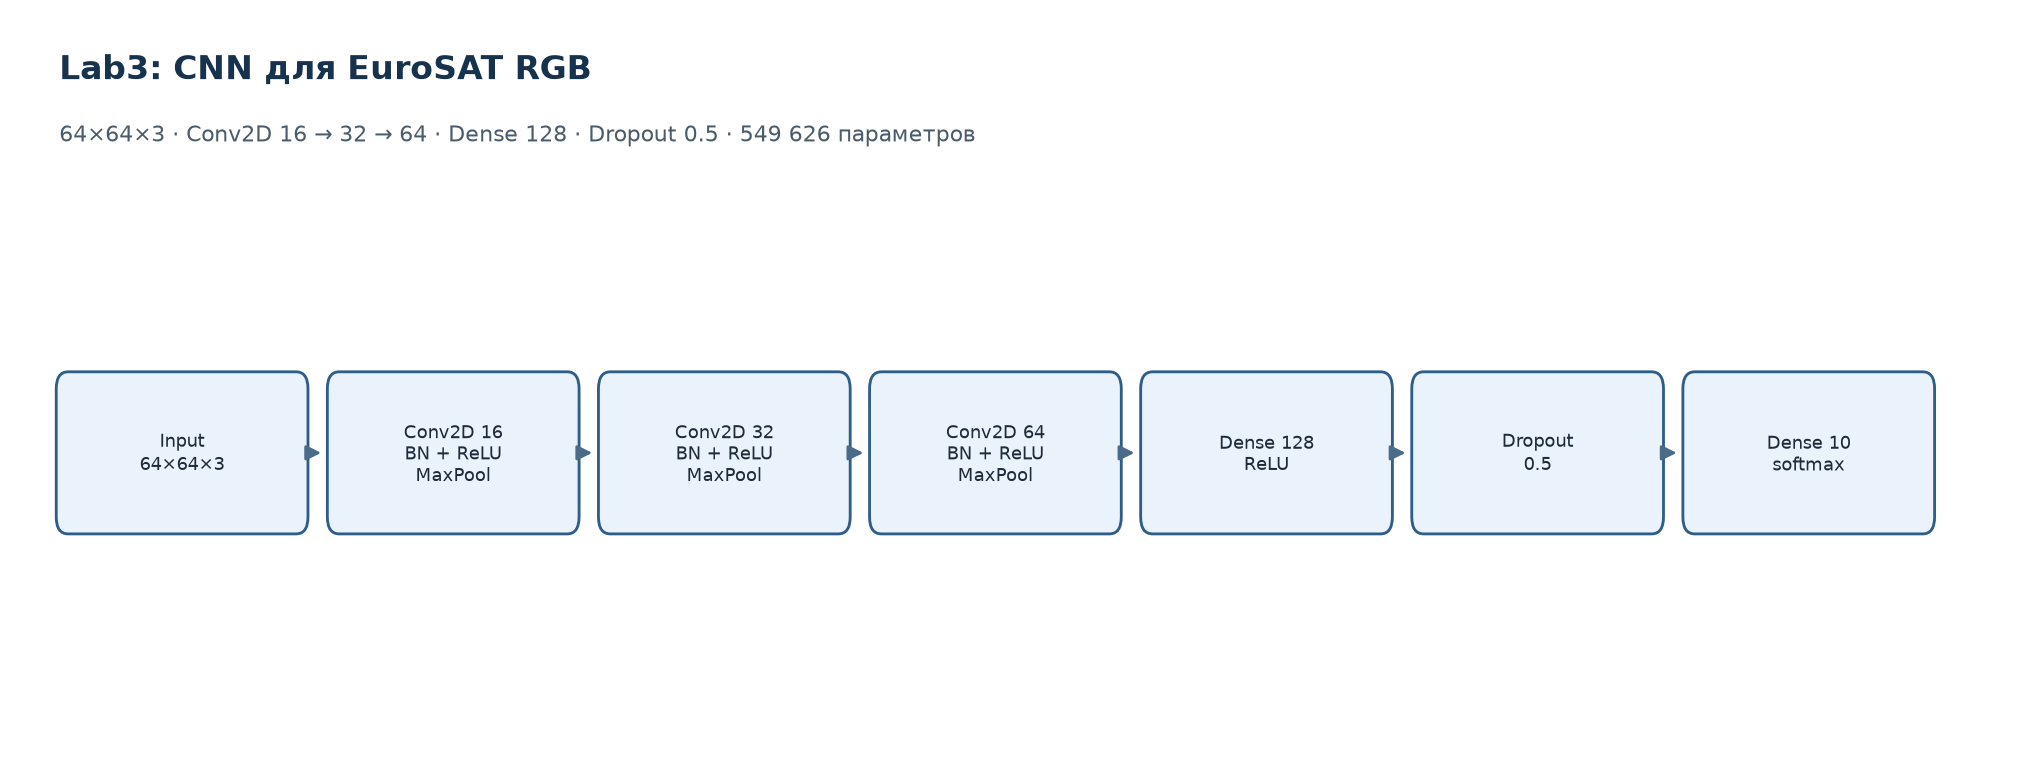

In [7]:
show_png(PROJECT / "docs_new" / "figures" / "model_architecture.png", 900)

## 8. Оценка

**Метрики.** Accuracy — доля верных ответов; при дисбалансе может завышать качество. Macro-F1 — F1 по каждому классу, затем среднее; каждый класс весит одинаково, поэтому провал редкого класса виден. Per-class precision / recall / F1 — качество по каждому из 10 классов. Confusion matrix — таблица 10×10, показывает, какие классы путаются.

| Прогон | accuracy | macro-F1 | Эпох | Лучшая эпоха | Время |
|---|---:|---:|---:|---:|---:|
| Основной, `patience=3` | 0.689877 | 0.670269 | 5 | 2 | 132.7 с |
| Контрольный, `patience=50` | 0.907901 | 0.905456 | 50 | 26 | 1 271.3 с |

**Важно.** 0.9079 — контрольный прогон, запущенный после того, как основной test 0.6899 уже был известен. Это не независимая проверка: test открывался дважды. 0.6899 — канонический результат `metrics_eurosat.json`; 0.9079 показывается отдельно как контроль протокола остановки.

In [8]:
primary = json.loads((REPORTS / "metrics_eurosat.json").read_text(encoding="utf-8"))
control = json.loads((CONTROL / "metrics_eurosat_patience_max.json").read_text(encoding="utf-8"))

rows = [
    {"run": "primary patience=3", "accuracy": primary["test"]["accuracy"], "macro_f1": primary["test"]["macro_f1"],
     "epochs": primary["epochs_ran"], "best_epoch": primary["early_stopping_epoch"], "time_s": primary["train_seconds"]},
    {"run": "control patience=50", "accuracy": control["test"]["accuracy"], "macro_f1": control["test"]["macro_f1"],
     "epochs": control["total_epochs_run"], "best_epoch": control["best_epoch"], "time_s": control["training_time_sec"]},
]
display(pd.DataFrame(rows).round(6))
print("primary val:", round(primary["val"]["accuracy"], 6), round(primary["val"]["macro_f1"], 6))
print("control val:", round(control["val"]["accuracy"], 6), round(control["val"]["macro_f1"], 6))

,run,accuracy,macro_f1,epochs,best_epoch,time_s
0,primary patience=3,0.689877,0.670269,5,2,132.7
1,control patience=50,0.907901,0.905456,50,26,1271.3


primary val: 0.698765 0.677616
control val: 0.90963 0.906517


**Что на графике.** Распределение классов EuroSAT: от 2 000 до 3 000 снимков. Примеры снимков разных классов: 64×64, RGB; видно, что растительные классы похожи по текстуре. Стратифицированный split 70/15/15: доли классов сохранены во всех частях.

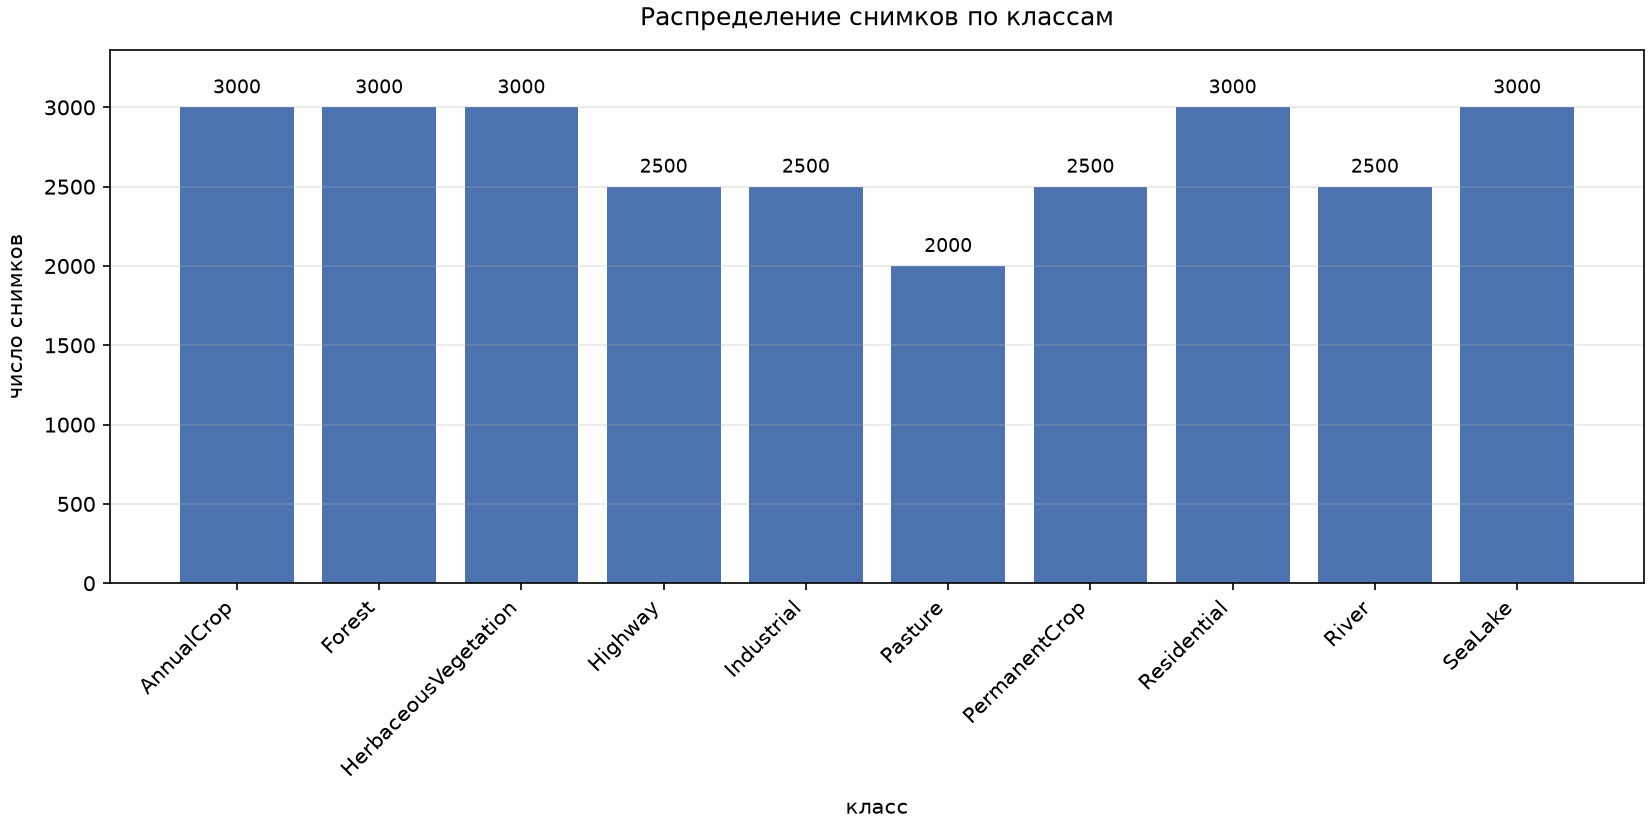

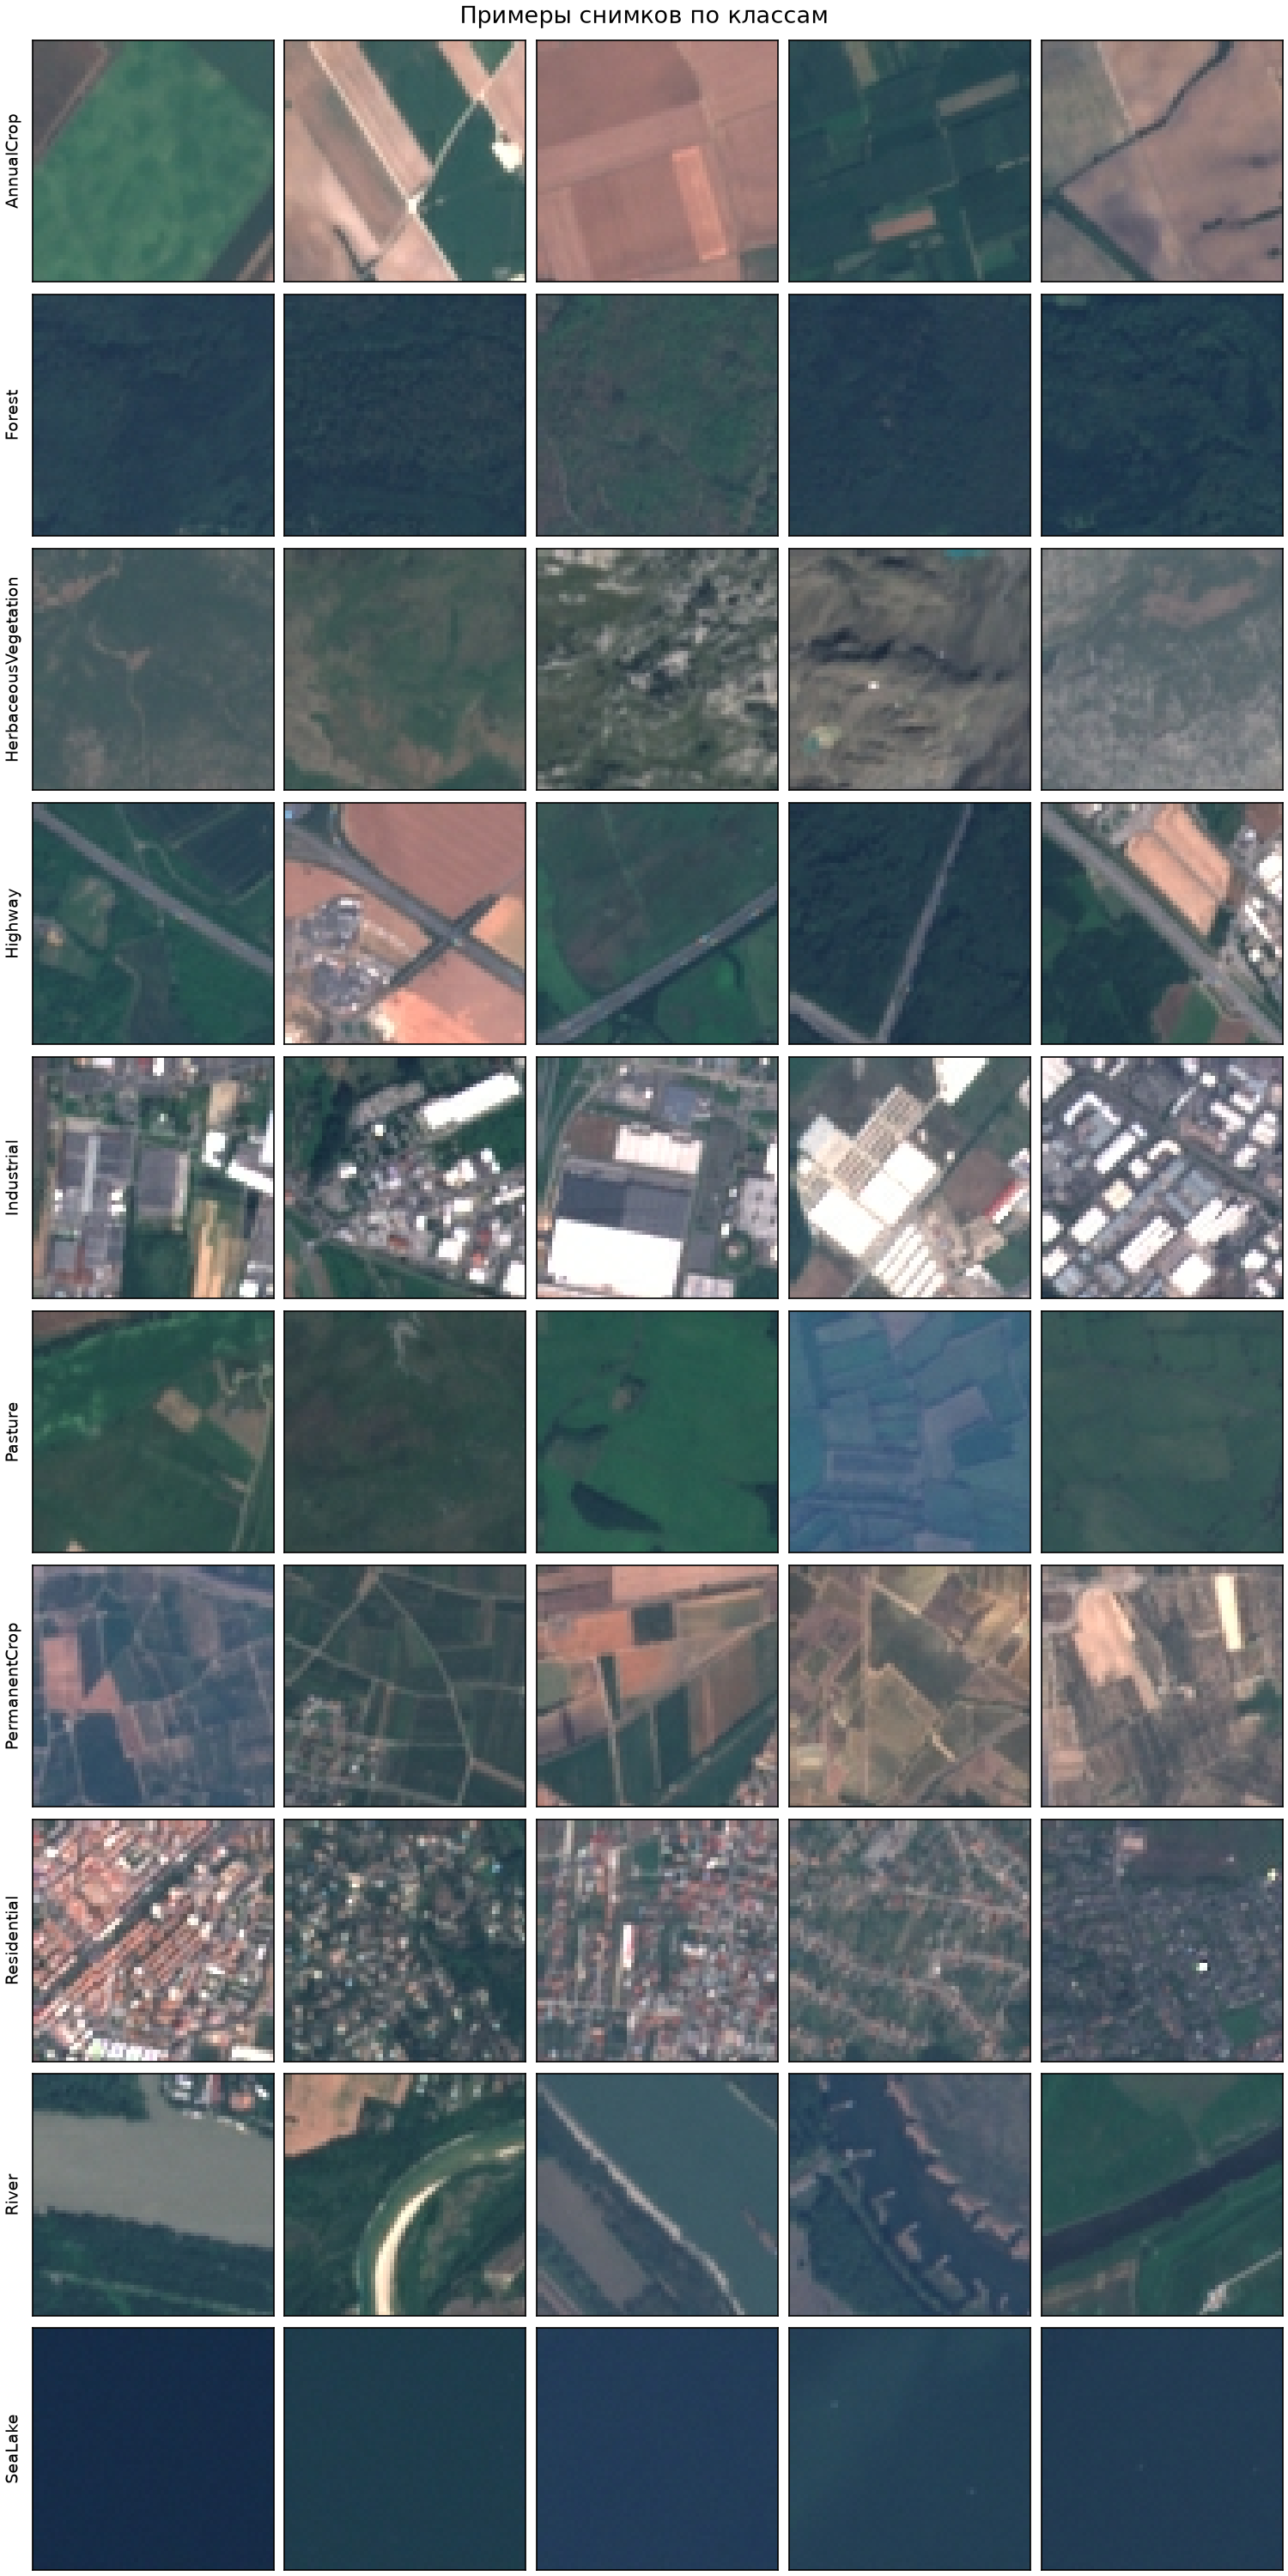

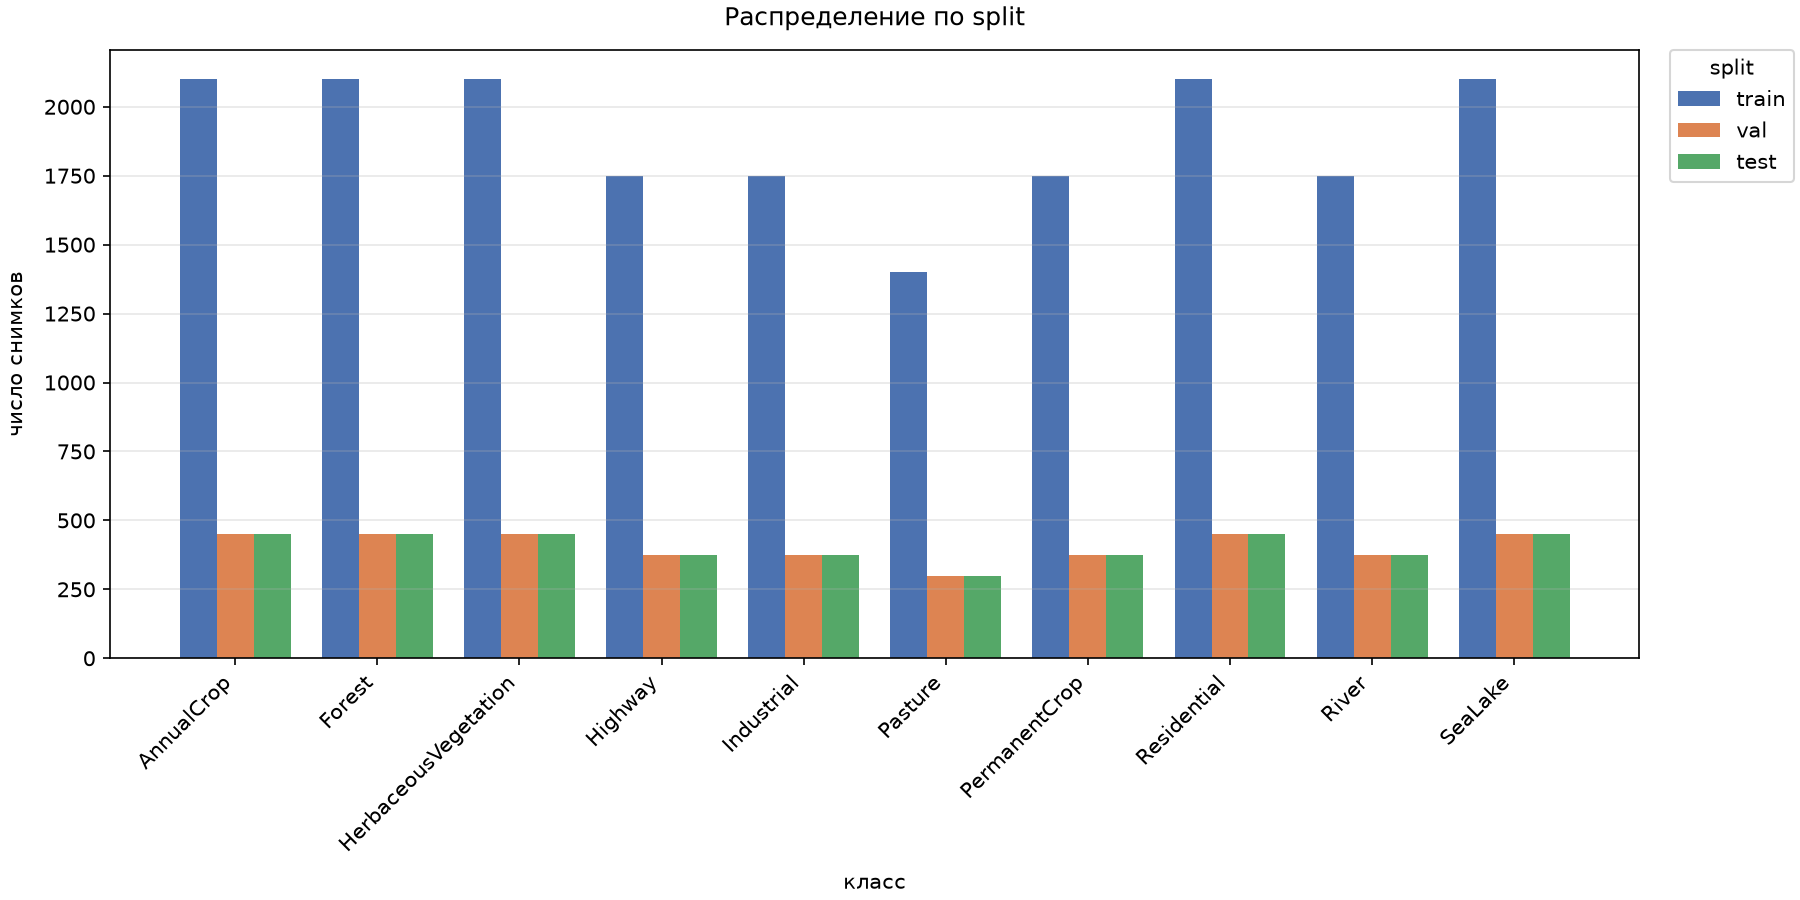

In [9]:
show_png("01_class_distribution.png", 800)
show_png("02_examples.png", 900)
show_png("03_split_distribution.png", 900)

### 8.1. Подгруппы

Per-class F1 контрольного прогона показывает, что слабые классы остались слабыми:

| Класс | Precision | Recall | F1 | Support |
|---|---:|---:|---:|---:|
| AnnualCrop | 0.9388 | 0.8867 | 0.9120 | 450 |
| Forest | 0.9454 | 0.9622 | 0.9537 | 450 |
| HerbaceousVegetation | 0.7473 | 0.9400 | 0.8327 | 450 |
| Highway | 0.9322 | 0.8800 | 0.9053 | 375 |
| Industrial | 0.9100 | 0.9707 | 0.9394 | 375 |
| Pasture | 0.9394 | 0.8267 | 0.8794 | 300 |
| PermanentCrop | 0.8683 | 0.7387 | 0.7983 | 375 |
| Residential | 0.9644 | 0.9622 | 0.9633 | 450 |
| River | 0.8907 | 0.8907 | 0.8907 | 375 |
| SeaLake | 0.9909 | 0.9689 | 0.9798 | 450 |

Самый слабый класс — `PermanentCrop` (F1 0.7983), затем `HerbaceousVegetation` (0.8327) и `Pasture` (0.8794). Основная ошибка — `PermanentCrop → HerbaceousVegetation`, 63 снимка. Оба класса — растительность, различие в геометрии полей, а на 64×64 пикселях её видно плохо.

По сравнению с основным прогоном слабые классы выросли сильнее всего: `PermanentCrop` 0.4898 → 0.7983, `HerbaceousVegetation` 0.5244 → 0.8327, `Highway` 0.3391 → 0.9053. Это ещё раз показывает, что основной прогон был недообучен, а не «упёрся в потолок архитектуры».

In [10]:
pc = pd.DataFrame(control["test"]["per_class"])
display(pc[["class_name", "precision", "recall", "f1", "support"]].round(4))
print("Самый слабый класс:", pc.loc[pc["f1"].idxmin(), "class_name"],
      round(pc["f1"].min(), 4))

,class_name,precision,recall,f1,support
0,AnnualCrop,0.9388,0.8867,0.9120,450
1,Forest,0.9454,0.9622,0.9537,450
2,HerbaceousVegetation,0.7473,0.9400,0.8327,450
3,Highway,0.9322,0.8800,0.9053,375
4,Industrial,0.9100,0.9707,0.9394,375
5,Pasture,0.9394,0.8267,0.8794,300
6,PermanentCrop,0.8683,0.7387,0.7983,375
7,Residential,0.9644,0.9622,0.9633,450
8,River,0.8907,0.8907,0.8907,375
9,SeaLake,0.9909,0.9689,0.9798,450


Самый слабый класс: PermanentCrop 0.7983


**Что на графике.** Confusion matrix основного прогона: основная путаница в растительных классах. Confusion matrix контрольного прогона: 0.9079 accuracy, ошибки сместились, но `PermanentCrop` остаётся слабым. Per-class F1 основного прогона: `PermanentCrop` 0.4898, `Highway` 0.3391 — недообучение, а не предел архитектуры.

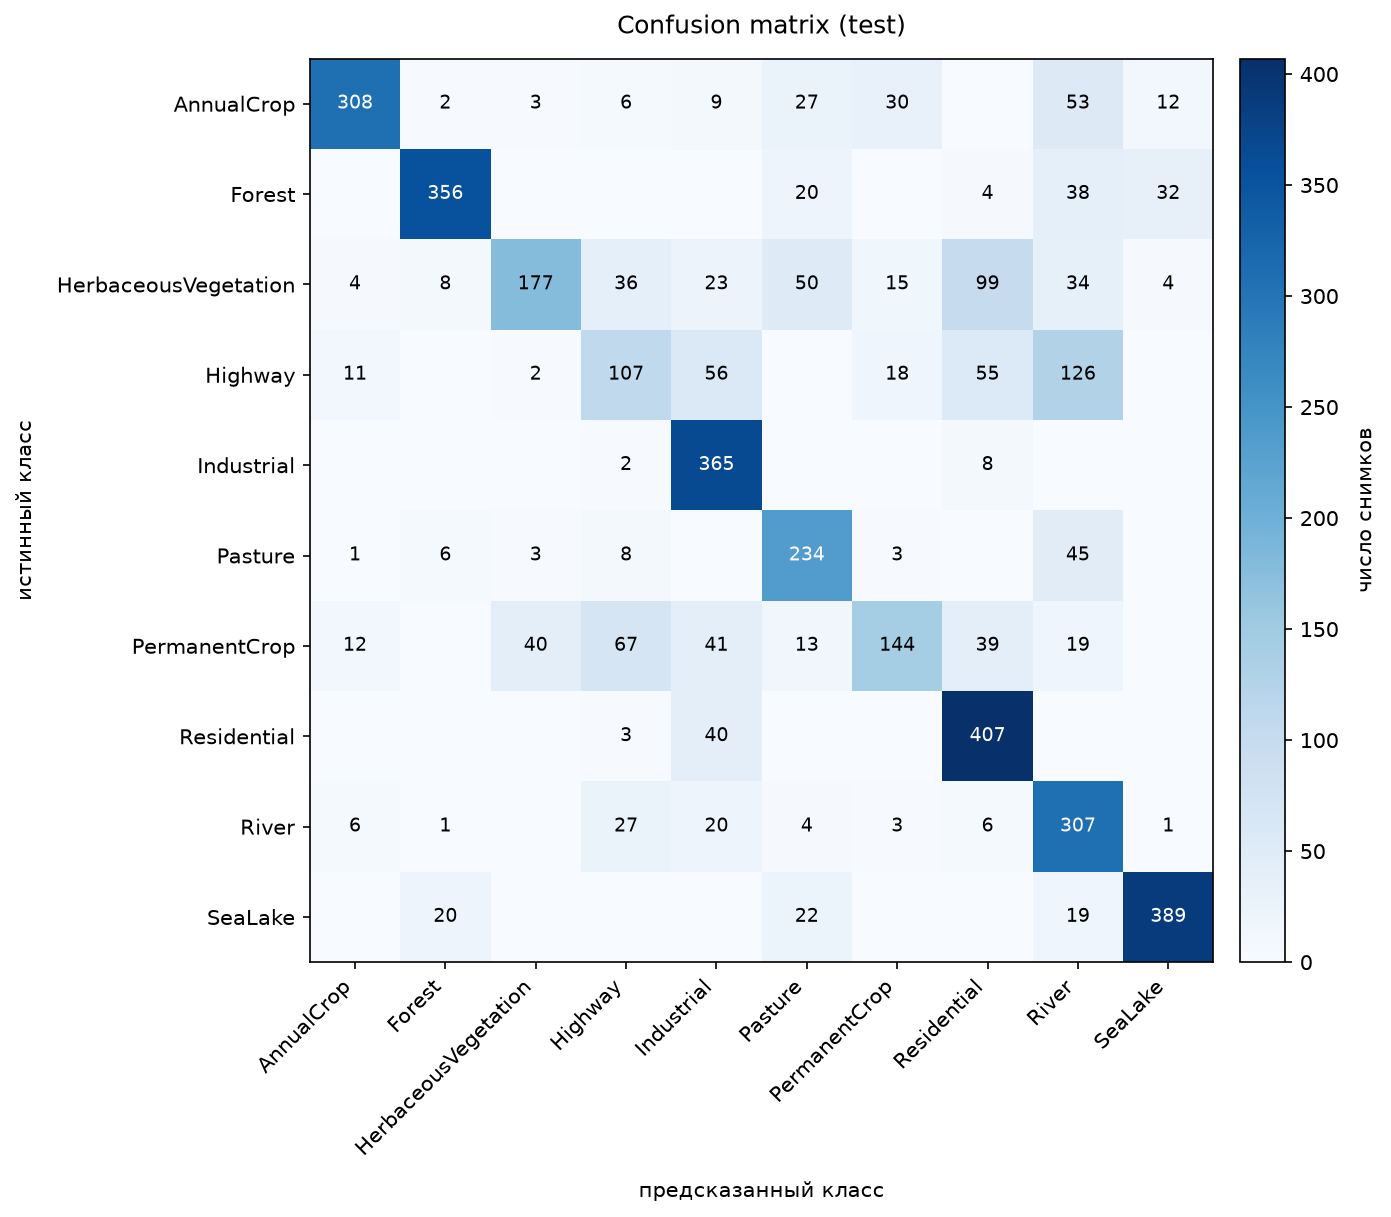

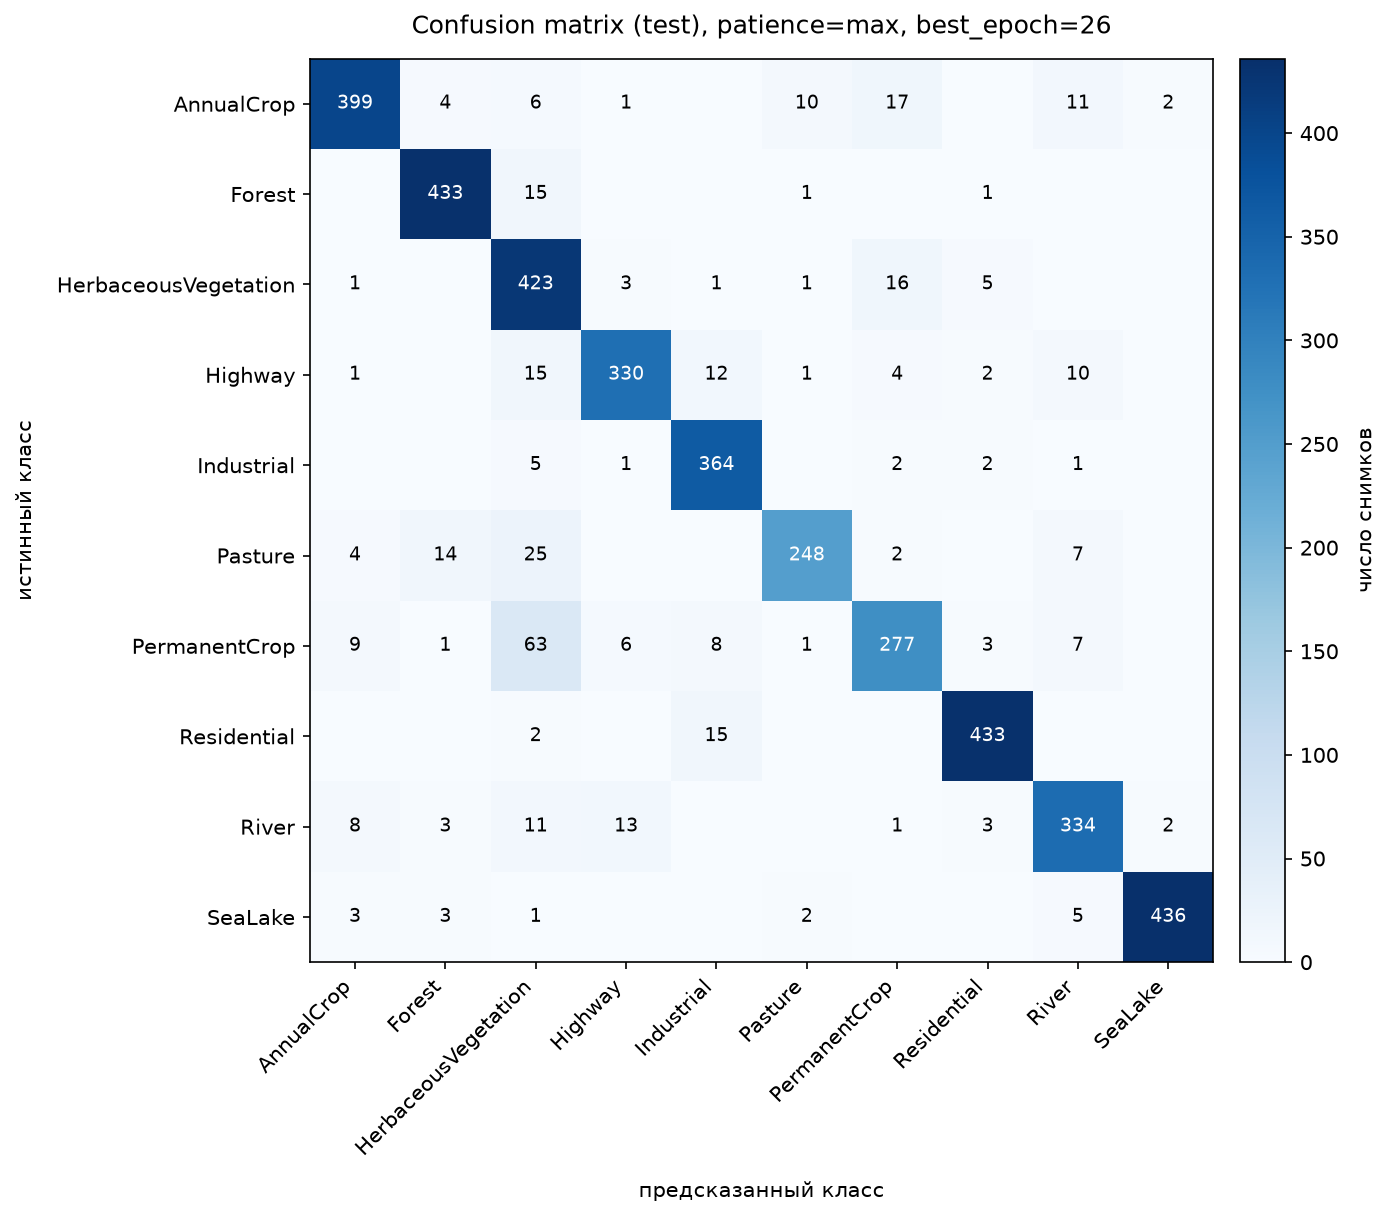

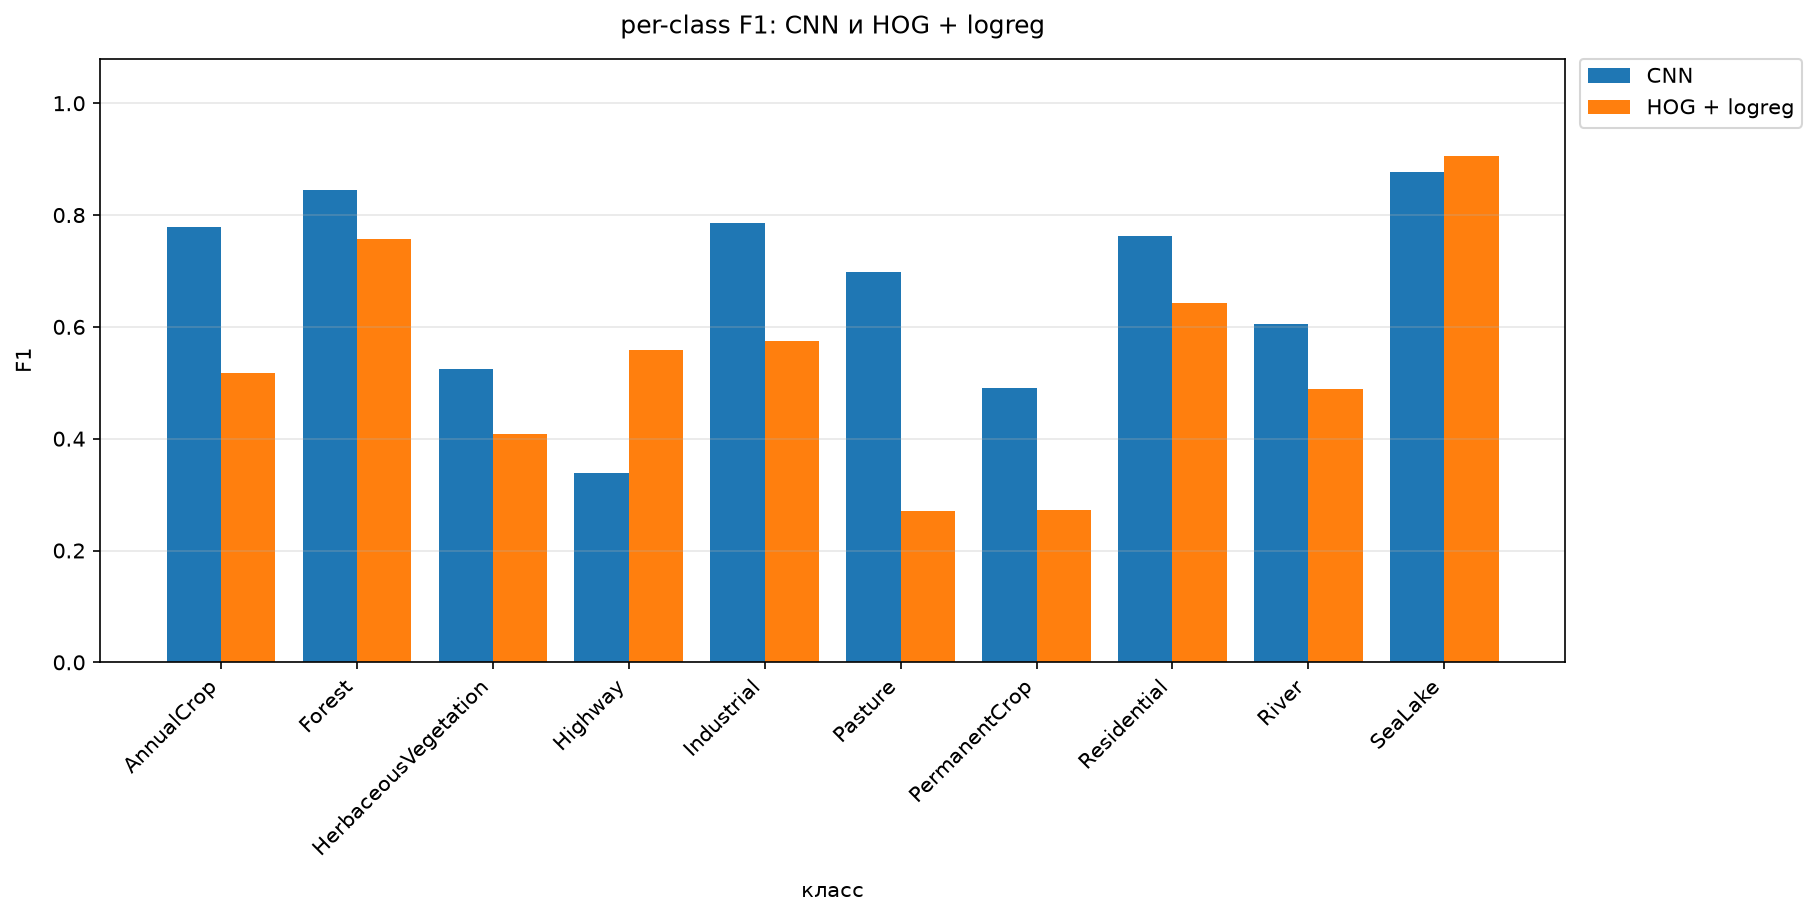

In [11]:
show_png("04_confusion_matrix.png", 900)
show_png(CONTROL / "figures" / "confusion_matrix_patience_max.png", 900)
show_png("06_per_class_f1.png", 900)

### 8.2. Разброс и неопределённость

Есть только один seed и один контрольный прогон, поэтому доверительный интервал не оценивался. Test использовался дважды: сначала для основного прогона, потом для контрольного, поэтому он не полностью «слепой». Повторных прогонов с другими seed нет, и разброс модели неизвестен.

| Источник неопределённости | Что это значит |
|---|---|
| Один seed | нельзя отделить эффект модели от удачного запуска |
| Test открывался дважды | контрольный результат не является независимой проверкой |
| Нет CI | 0.9055 — точечная оценка, а не интервал |
| Нет `scene_id` | нельзя исключить пересечение по сцене |
| 55 near-duplicate `SeaLake` | F1 0.9798 для SeaLake может быть оптимистичным |

**Что на графике.** Кривые обучения основного прогона: loss и accuracy по эпохам; обучение остановилось на 5-й эпохе, лучшая — 2-я. Контрольный прогон: 50 эпох, лучшая 26-я; validation accuracy 0.9096, macro-F1 0.9065. Кривые показывают, что разница 0.6899/0.9079 объясняется протоколом остановки, а не изменением архитектуры.

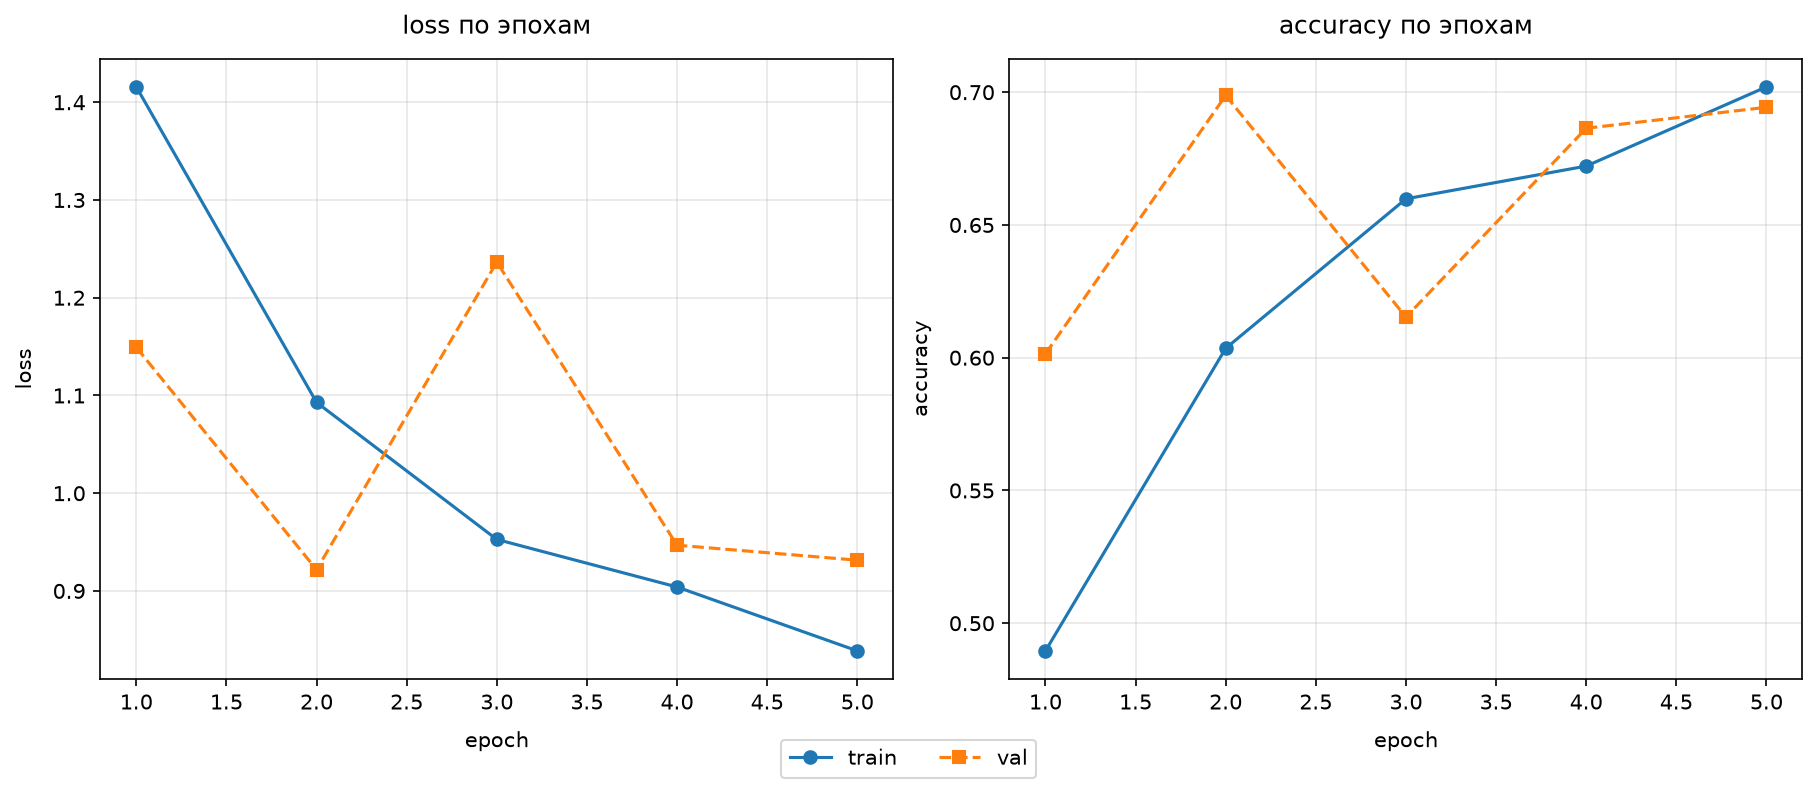

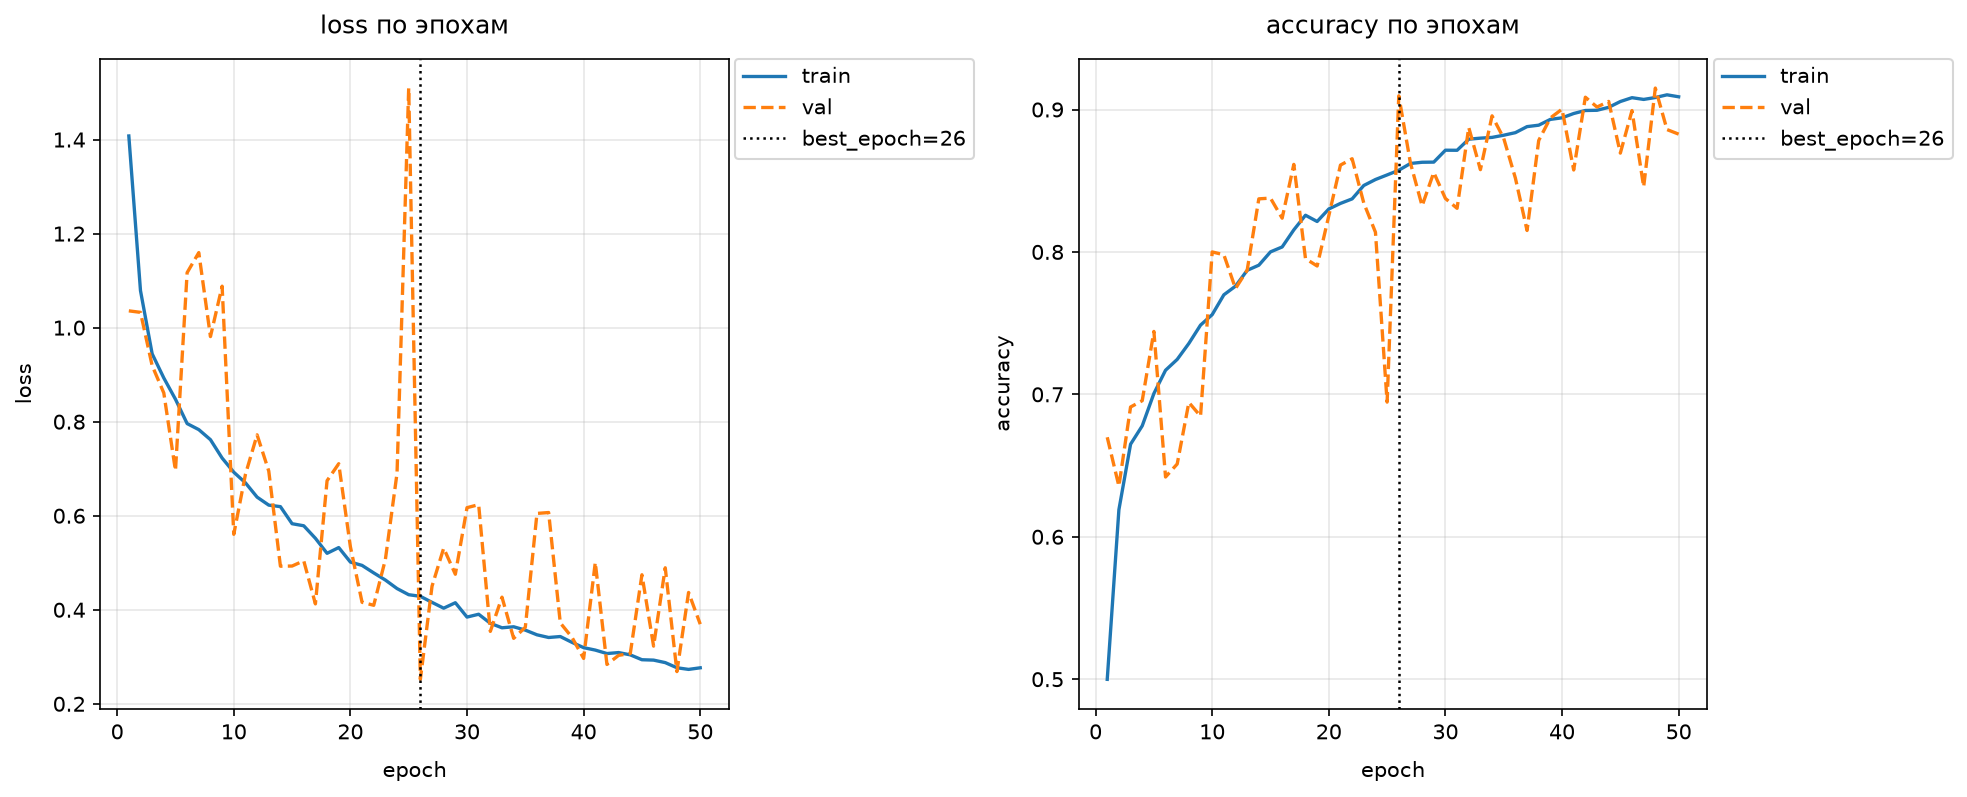

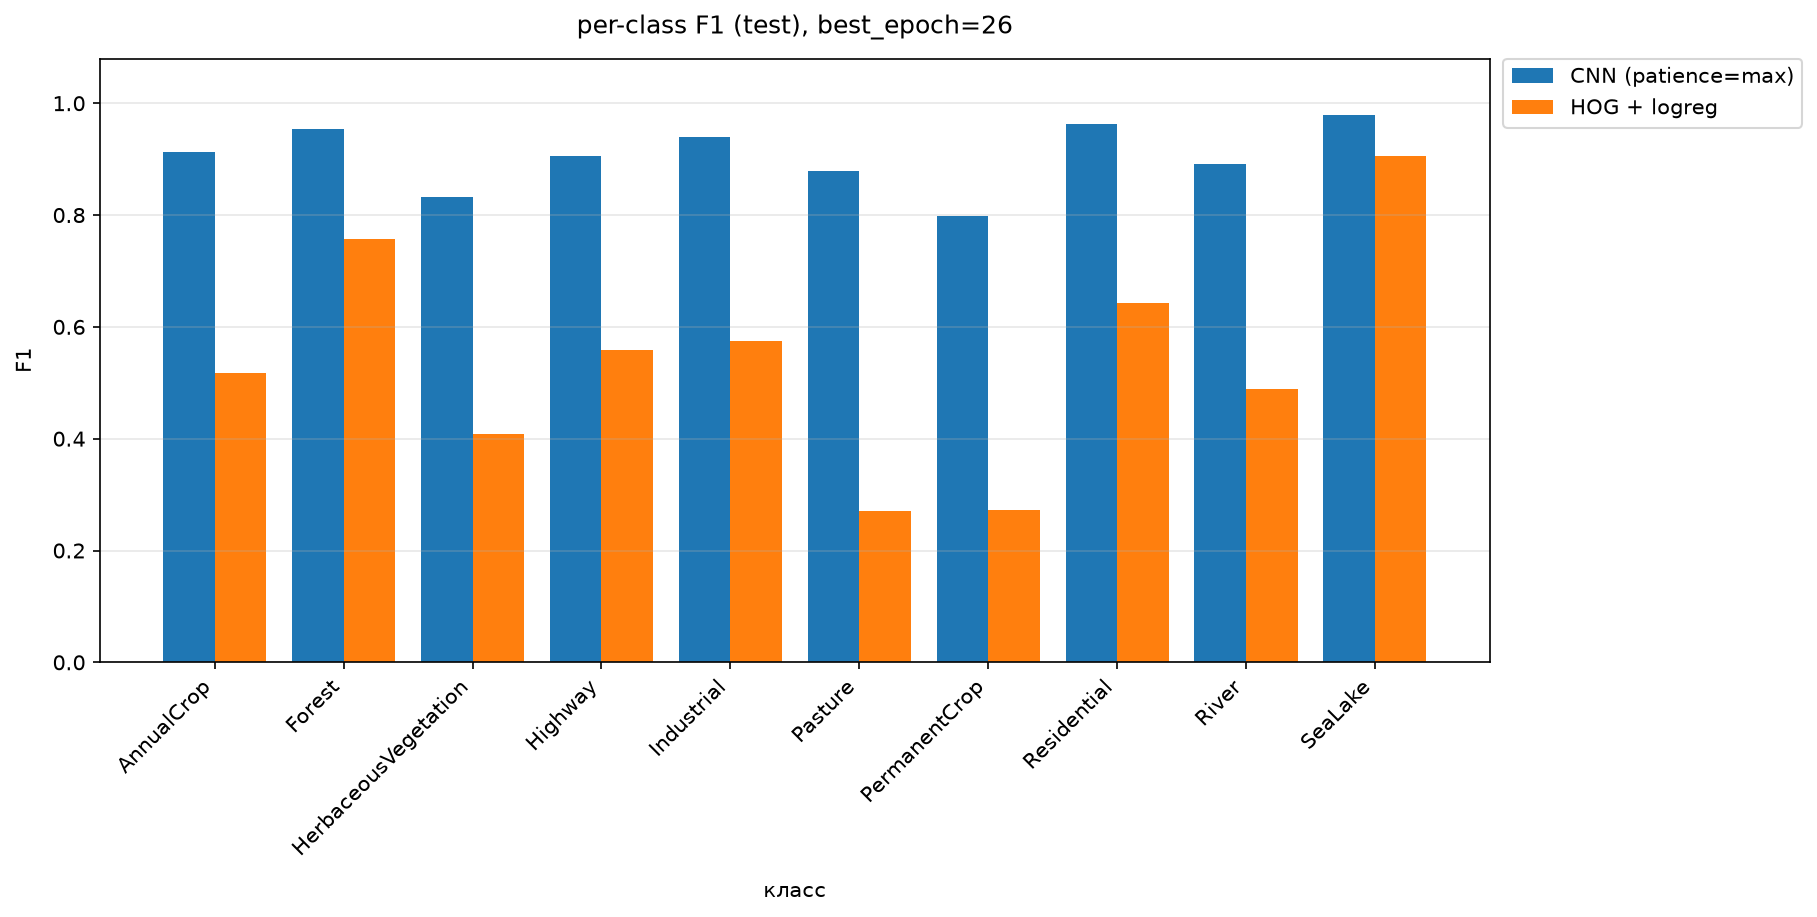

In [12]:
show_png("05_training_curves.png", 900)
show_png(CONTROL / "figures" / "training_curves_patience_max.png", 900)
show_png(CONTROL / "figures" / "per_class_f1_patience_max.png", 900)

## 9. Baseline и сравнение

| Модель | accuracy | macro-F1 | Комментарий |
|---|---:|---:|---|
| majority | 0.111111 | 0.020000 | всегда самый частый класс |
| random | 0.097037 | 0.096760 | случайный выбор из 10 классов |
| HOG + logreg | 0.557037 | 0.539698 | ручные признаки границ |
| CNN, `patience=3` | 0.689877 | 0.670269 | недообучена из-за остановки |
| **CNN, `patience=50`** | **0.907901** | **0.905456** | контрольный прогон |

CNN лучше HOG + logreg на 35.1 процентного пункта по accuracy и на 36.6 п.п. по macro-F1. HOG описывает только направления границ: у воды и леса текстура богатая, а у полей и пастбищ различие в мелкой геометрии, которую HOG теряет.

In [13]:
base = json.loads((REPORTS / "summary_baselines.json").read_text(encoding="utf-8"))
rows = [
    {"model": "majority", **{k: base["majority"][k] for k in ["accuracy", "macro_f1"]}},
    {"model": "random", **{k: base["random"][k] for k in ["accuracy", "macro_f1"]}},
    {"model": "HOG + logreg", **{k: base["hog_logreg"][k] for k in ["accuracy", "macro_f1"]}},
    {"model": "CNN primary", **{k: base["cnn"][k] for k in ["accuracy", "macro_f1"]}},
    {"model": "CNN control", "accuracy": control["test"]["accuracy"], "macro_f1": control["test"]["macro_f1"]},
]
display(pd.DataFrame(rows).round(6))

,model,accuracy,macro_f1
0,majority,0.111111,0.020000
1,random,0.097037,0.096760
2,HOG + logreg,0.557037,0.539698
3,CNN primary,0.689877,0.670269
4,CNN control,0.907901,0.905456


**Что на графике.** CNN против majority, random и HOG + logreg: accuracy и macro-F1. CNN значительно выше всех baseline; HOG + logreg — сильнейший простой baseline, но ему не хватает текстурных признаков.

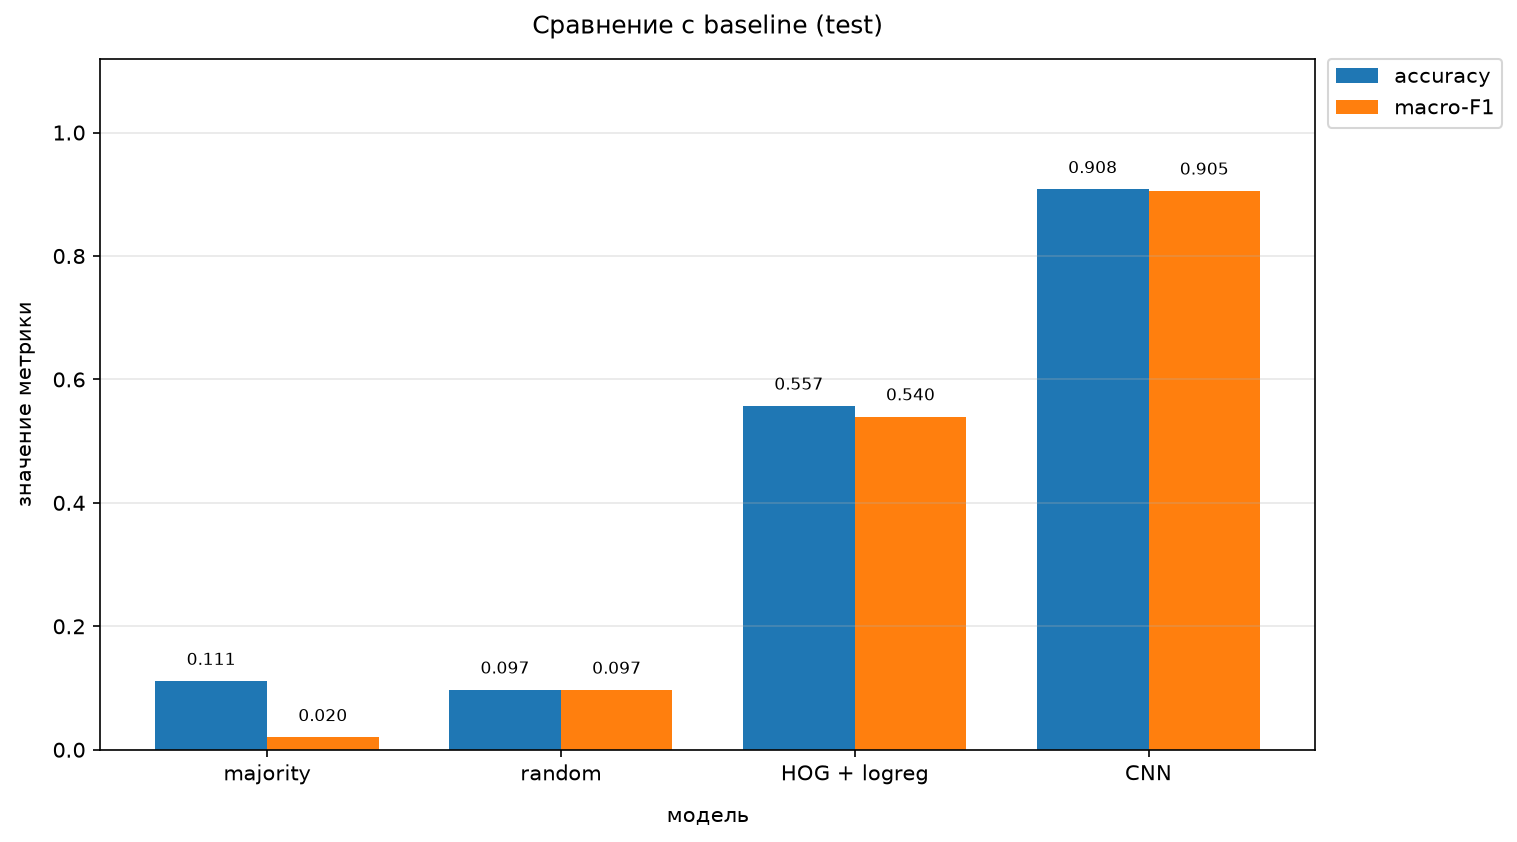

In [14]:
show_png("07_baseline_comparison.png", 900)

### 9.1. Абляции

| Эксперимент | Что изменено | accuracy | macro-F1 | Вывод |
|---|---|---:|---:|---|
| Основной | `patience=3`, 20 эпох | 0.689877 | 0.670269 | остановка на 5-й эпохе |
| Контрольный | `patience=50`, 50 эпох | 0.907901 | 0.905456 | тот же код, другой протокол |
| HOG + logreg | ручные признаки | 0.557037 | 0.539698 | CNN лучше |
| majority | константа | 0.111111 | 0.020000 | не различает классы |
| random | случайно | 0.097037 | 0.096760 | около 1/10 |

Это не абляция архитектуры: менялся только протокол остановки. Нельзя утверждать, что «архитектура способна на большее»; можно утверждать, что основной прогон был недообучен.

## 10. Диагностика

### 10.1. Анализ ошибок

Главная ошибка контрольного прогона — `PermanentCrop → HerbaceousVegetation` (63 снимка). Дальше идут `Pasture → HerbaceousVegetation` (25), `AnnualCrop → PermanentCrop` (17), `HerbaceousVegetation → PermanentCrop` (16), `Forest → HerbaceousVegetation` (15) и `Highway → HerbaceousVegetation` (15). Почти все ошибки связаны с растительностью: на 64×64 текстура и цвет похожи, а границы полей размыты.

`SeaLake` почти идеален (F1 0.9798), но именно в этом классе найдены почти-дубликаты. Это не обязательно утечка: md5 у файлов разные, а `scene_id` нет. Но метрику SeaLake стоит считать оптимистичной.

### 10.2. Важность признаков и near-duplicate

CNN не даёт таблицы важности признаков. Вместо этого проверялась близость test→train по 128-мерным эмбеддингам: средняя top-1 cosine similarity 0.9833, медиана 0.9905, 3 768 test-снимков имеют сходство > 0.95. Это ожидаемо для однородного датасета, но не доказывает утечку.

dHash-проверка: 179 пар с расстоянием ≤ 4 бита, 116 пар ≤ 2 бита, 66 точных совпадений по dHash; 55 пар с MAD < 5 — все `SeaLake`. В датасете нет `scene_id`, поэтому нельзя отличить «тот же участок после сжатия» от «соседнего участка той же сцены».

In [15]:
probe = json.loads((REPORTS / "overlap_probe.json").read_text(encoding="utf-8"))
print("top1 cosine mean/median:", round(probe["top1_similarity"]["mean"], 4), round(probe["top1_similarity"]["median"], 4))
print("counts > 0.95:", probe["counts_above"]["gt_0.95"])
print("dHash pairs <= 4:", probe["phash_near_duplicates"]["pairs_le_4_bits"])
print("dHash pairs <= 2:", probe["phash_near_duplicates"]["pairs_le_2_bits"])
print("exact dHash:", probe["phash_near_duplicates"]["exact_duplicates"])
print("MAD < 5:", probe["phash_near_duplicates"]["mad_lt_5_class_share"])
print("same class share > 0.95:", probe["same_class_share_above_0.95"])

top1 cosine mean/median: 0.9833 0.9905
counts > 0.95: 3768
dHash pairs <= 4: 179
dHash pairs <= 2: 116
exact dHash: 66
MAD < 5: {'SeaLake': 55}
same class share > 0.95: 0.9318


**Что на графике.** 55 почти-дубликатов SeaLake: пары test/train с MAD < 5; сходство высокое, класс один и тот же. Это возможная утечка по сцене: md5 разные, `scene_id` нет, поэтому доказать независимость нельзя.

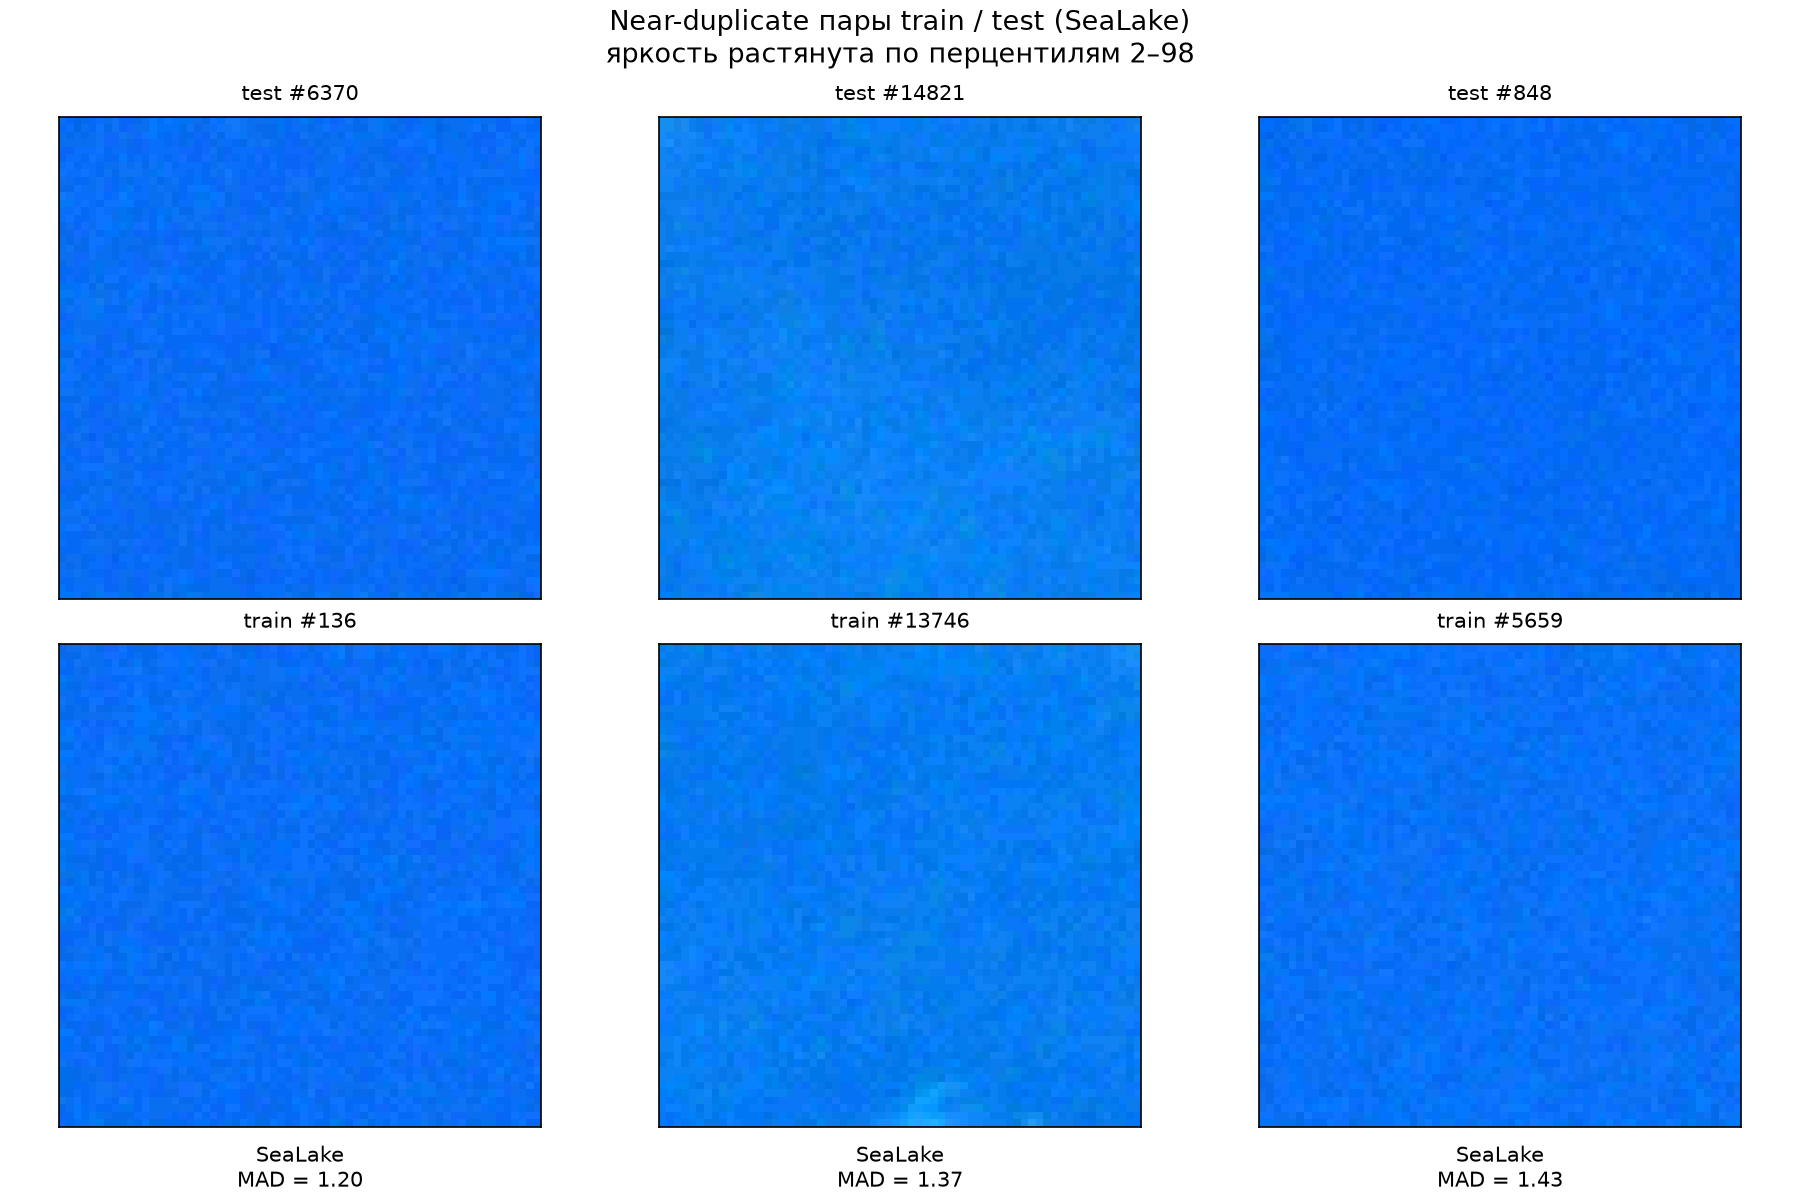

In [16]:
show_png("08_near_duplicates.png", 900)

### 10.3. Что подтверждено, что нет

**Подтверждено.**
- Данные чистые: 27 000 снимков, 10 классов, нет битых файлов и md5-дубликатов.
- Split стратифицирован и не пересекается; нормализация и аугментация используют только train.
- CNN значительно лучше majority, random и HOG + logreg.
- Контрольный прогон с `patience=50` даёт 0.907901 accuracy и 0.905456 macro-F1.
- Разница между 0.6899 и 0.9079 объясняется протоколом остановки: менялись только `patience` и число эпох.

**Не подтверждено.**
- 0.9079 не доказывает, что архитектура «способна на большее»: не было абляций глубины, ширины и learning rate.
- 0.9079 не является несмещённой оценкой: test открывался дважды.
- Нет доверительного интервала: один seed, один контрольный прогон.
- `SeaLake` F1 0.9798 не гарантирует независимость: 55 near-duplicate пар, нет `scene_id`.
- Не доказано, что модель переносится на снимки другого сезона, региона или разрешения.

### 10.4. Ограничения

| Ограничение | Что ломается | Разрешимо |
|---|---|---|
| Один seed | нет оценки разброса | да, повторные прогоны |
| Test открывался дважды | оценка не полностью слепая | нет, если не собрать новый test |
| Нет `scene_id` | нельзя исключить пересечение по сцене | нет, метаданных нет |
| 55 near-duplicate `SeaLake` | F1 SeaLake оптимистичен | частично, можно исключить пары |
| Разрешение 64×64 | слабые растительные классы | да, проверить 128×128 |
| Нет learning rate schedule | возможно недообучение | да, отдельный эксперимент |
| Нет абляций архитектуры | нельзя говорить о её пределе | да, отдельные эксперименты |

**Риски утечки.** Нормализация посчитана только по train; аугментация только train; индексы split зафиксированы, пересечений нет. Near-duplicate `SeaLake` — потенциальная утечка по сцене, но доказать нельзя. Test использовался для основного и контрольного прогонов: это не утечка в обучение, но ослабляет независимость оценки.

## 11. Выводы

1. CNN с нуля решает EuroSAT заметно лучше HOG + logreg: 0.9055 против 0.5397 macro-F1 (контрольный прогон).
2. Основной прогон с `patience=3` был недообучен: 0.6703 macro-F1, остановка на 5-й эпохе.
3. Контрольный прогон с `patience=50` даёт 0.9055, но это точечная оценка на одном seed; test открывался дважды.
4. Слабые классы — `PermanentCrop` и `HerbaceousVegetation`; ошибки связаны с похожей растительностью на 64×64.
5. Главные ограничения — отсутствие `scene_id`, 55 near-duplicate `SeaLake`, один seed и повторное использование test.

### 11.1. Использованные методы

| Метод | Где применяется | Зачем |
|---|---|---|
| TFDS `eurosat/rgb` | загрузка данных | локальный кэш без сети после первого скачивания |
| Проверка md5 и размеров | контроль данных | исключить битые и дублирующиеся файлы |
| Стратифицированный split | разбиение | сохранить доли классов |
| Нормализация по train | препроцессинг | не допустить утечку статистики test |
| Аугментация train | регуляризация | повысить вариативность без изменения класса |
| CNN `Conv2D(16,32,64)` | моделирование | выучить иерархию признаков из пикселей |
| BatchNorm + ReLU + MaxPool | архитектура | стабилизировать и ускорить обучение |
| Dropout 0.5 | регуляризация | снизить переобучение в полносвязном слое |
| EarlyStopping и checkpoint | обучение | остановиться и вернуть лучшие веса |
| macro-F1 | оценка | учесть все классы одинаково |
| Per-class F1 и confusion matrix | анализ | найти слабые классы и направления ошибок |
| HOG + logreg | baseline | проверить, нужна ли CNN |
| dHash и cosine similarity | проверка | искать near-duplicate и пересечение по сцене |

### 11.2. Артефакты

| Артефакт | Путь | Назначение |
|---|---|---|
| Проверка данных | `reports/data_check.json` | размер, классы, распределение |
| Split | `reports/split_info.json` | индексы и seed |
| Нормализация | `reports/normalization_stats.json` | mean/std по train |
| Проверка утечек | `reports/leakage_check.json` | пересечения и области применения |
| Baseline | `reports/baseline_metrics.json` | majority, random, HOG + logreg |
| Метрики CNN | `reports/metrics_eurosat.json` | test, val, per-class, confusion |
| Сводка | `reports/summary_baselines.json` | accuracy и macro-F1 всех моделей |
| Модель | `reports/eurosat_cnn.keras` | веса основного прогона |
| Контроль | `reports/control_patience_max/` | JSON, модель, графики |
| Near-duplicate | `reports/overlap_probe.json` | 55 пар и эмбеддинги |
| Графики | `reports/figures/` | 8 рисунков |

**Команды воспроизведения.** `python scripts/download_eurosat.py` — однократно; `python scripts/build_artifacts.py` — data_check, split, normalization, leakage; `python scripts/run_baselines.py` — majority, random, HOG + logreg; `python scripts/train_cnn.py` — основной прогон; `python scripts/make_model_figures.py` — рисунки 04–07; `python scripts/train_cnn_patience_max.py` — контрольный прогон; `python scripts/make_control_figures.py` — рисунки контроля; `python scripts/overlap_probe.py` — near-duplicate пары; `python scripts/make_overlap_figure.py` — рисунок 08; `python scripts/build_lab3_report.py` — HTML-отчёт; `python -m pytest tests -q` — тесты.

**Итог.** Ноутбук воспроизводит все содержательные разделы отчёта: данные и проверки, split, нормализацию, архитектуру, оба протокола остановки, метрики, per-class анализ, baseline, near-duplicate, ограничения и выводы. Канонический результат — `metrics_eurosat.json`: accuracy 0.689877, macro-F1 0.670269. Контрольный 0.907901 / 0.905456 показан отдельно как пост-тестовый протокол, а не как главный результат.